## Построение воспроизводимого пайплайна обработки данных и инжиниринг признаков

### Предметный разведочный анализ данных

**Цель анализа:** изучить исходную часть набора Student Performance, оценить качество данных, выявить взаимосвязи между характеристиками студентов и итоговой оценкой G3, а также проверить предметные гипотезы для последующего проектирования пайплайна.

In [70]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["font.family"] = "DejaVu Sans"
pd.set_option("display.max_columns", 40)

In [71]:
# Рабочая папка: либо корень проекта, либо директория notebooks.
project_root = Path.cwd().resolve()
if project_root.name.lower() == "notebooks":
    project_root = project_root.parent

data_path = project_root / "data" / "initial" / "initial.csv"
if not data_path.is_file():
    raise FileNotFoundError(
        f"Не найден {data_path}. Сначала запусти scripts/prepare_batches.py "
        "из корня репозитория."
    )

df = pd.read_csv(data_path)

# Результаты этого анализа сохраняем в отдельные папки.
import sys
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src1.report_paths import ReportDirectory
figures_dir = ReportDirectory(project_root, "figures")
tables_dir = ReportDirectory(project_root, "tables")
figures_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

def save_table(frame: pd.DataFrame, filename: str) -> None:
    frame.to_csv(tables_dir / filename, index=False, encoding="utf-8-sig")

print("Источник:", data_path.relative_to(project_root))
print("Форма данных:", df.shape)
display(df.head())

Источник: data\initial\initial.csv
Форма данных: (237, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,M,17,U,GT3,T,2,1,other,other,home,mother,2,1,3,yes,yes,no,yes,yes,no,yes,no,4,5,1,1,1,3,2,8,8,10
1,MS,M,18,R,LE3,T,1,2,at_home,services,other,father,3,1,0,no,yes,yes,yes,yes,no,yes,yes,4,3,3,2,3,3,3,14,12,12
2,GP,M,18,R,LE3,T,3,3,other,services,course,mother,1,2,1,no,yes,no,no,yes,yes,yes,yes,4,3,3,1,3,5,8,3,5,5
3,GP,F,16,U,GT3,A,2,1,other,other,other,mother,1,2,0,no,no,yes,yes,yes,yes,yes,yes,5,3,4,1,1,2,8,8,9,10
4,MS,M,20,U,LE3,A,2,2,services,services,course,other,1,2,2,no,yes,yes,no,yes,yes,no,no,5,5,4,4,5,4,11,9,9,9



### Структура исходных данных

Первоначально анализируется размер набора данных, типы переменных, количество уникальных значений и наличие пропусков. Эти сведения позволяют определить состав признаков и выбрать методы последующего исследования.

In [72]:

# Размер набора
print("Количество строк:", df.shape[0])
print("Количество столбцов:", df.shape[1])

# Формируем таблицу структуры данных
feature_info = pd.DataFrame({
    "Признак": df.columns,
    "Тип данных": df.dtypes.astype(str).values,
    "Уникальных значений": df.nunique().values,
    "Пропусков": df.isna().sum().values
})

display(feature_info)

# Сохраняем таблицу для отчёта
save_table(feature_info, "feature_structure.csv")

Количество строк: 237
Количество столбцов: 33


,Признак,Тип данных,Уникальных значений,Пропусков
0,school,str,2,0
1,sex,str,2,0
2,age,int64,7,0
3,address,str,2,0
4,famsize,str,2,0
5,Pstatus,str,2,0
6,Medu,int64,5,0
7,Fedu,int64,5,0
8,Mjob,str,5,0
9,Fjob,str,5,0



### Первичная проверка качества данных

Проверяется наличие пропущенных значений, полных дубликатов и значений, не соответствующих допустимым диапазонам. Результаты используются для формирования требований к качеству данных в подразделе 2.3.

In [73]:

# Количество пропусков
missing_count = df.isna().sum().sum()

# Количество полных дубликатов строк
duplicates_count = df.duplicated().sum()

# Проверка допустимых значений
invalid_values = {
    "G1": (~df["G1"].between(0, 20)).sum(),
    "G2": (~df["G2"].between(0, 20)).sum(),
    "G3": (~df["G3"].between(0, 20)).sum(),
    "studytime": (~df["studytime"].between(1, 4)).sum(),
    "failures": (~df["failures"].between(0, 3)).sum(),
    "absences": (df["absences"] < 0).sum()
}

print("Пропущенных значений:", missing_count)
print("Полных дубликатов:", duplicates_count)

print("\nНарушения допустимых диапазонов:")
display(pd.DataFrame(
    invalid_values.items(),
    columns=["Признак", "Количество нарушений"]
))


Пропущенных значений: 0
Полных дубликатов: 0

Нарушения допустимых диапазонов:


,Признак,Количество нарушений
0,G1,0
1,G2,0
2,G3,0
3,studytime,0
4,failures,0
5,absences,0


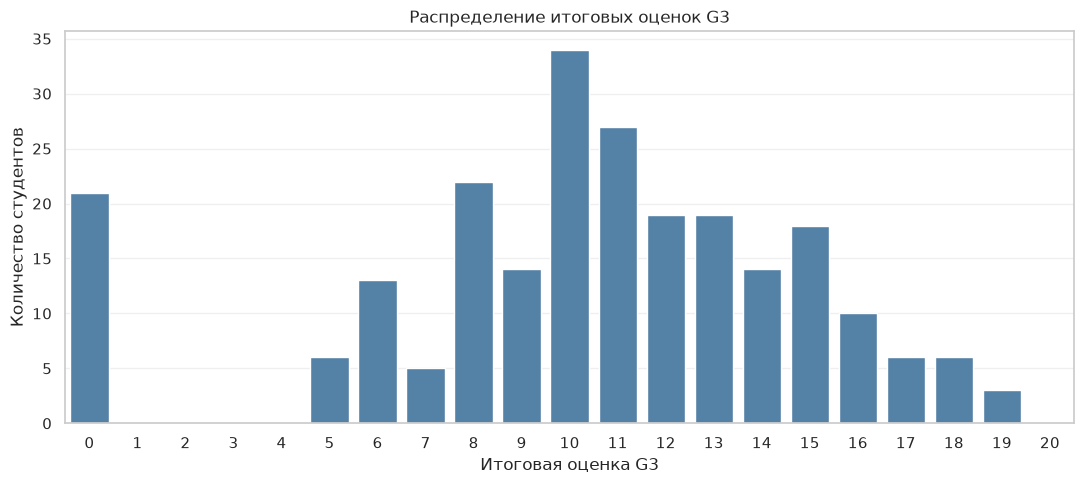

In [74]:

# Распределение итоговых оценок
grade_counts = df["G3"].value_counts().reindex(
    range(21), fill_value=0
).sort_index()

plt.figure(figsize=(11, 5))

sns.barplot(
    x=grade_counts.index,
    y=grade_counts.values,
    color="steelblue"
)

plt.title("Распределение итоговых оценок G3")
plt.xlabel("Итоговая оценка G3")
plt.ylabel("Количество студентов")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(figures_dir / "g3_distribution.png", dpi=200, bbox_inches="tight")
plt.show()


### Целевая переменная `G3`

`G3` — итоговая оценка по шкале 0–20. Задача нашего проекта — **регрессия**, а не классификация. Дополнительно используем порог `G3 < 10` только как предметный показатель риска: он **не изменяет** постановку регрессионной задачи.

Ниже вычисляются описательные статистики, частоты оценок и доля студентов с низкими итоговыми оценками.

In [75]:
g3_summary = df["G3"].describe().rename("G3").to_frame()
g3_summary.loc["median"] = df["G3"].median()
g3_summary.loc["zero_share_%"] = 100 * df["G3"].eq(0).mean()
g3_summary.loc["low_grade_share_%"] = 100 * df["G3"].lt(10).mean()

g3_frequency = (
    df["G3"].value_counts().reindex(range(21), fill_value=0)
    .rename_axis("G3").reset_index(name="Количество")
)
g3_frequency["Доля, %"] = (100 * g3_frequency["Количество"] / len(df)).round(2)

display(g3_summary.round(3))
display(g3_frequency)
save_table(g3_summary.reset_index().rename(columns={"index": "Статистика"}), "g3_statistics.csv")
save_table(g3_frequency, "g3_frequency.csv")

print(f"Доля наблюдений с G3 < 10: {df['G3'].lt(10).mean():.1%}")
print(f"Доля G3 = 0: {df['G3'].eq(0).mean():.1%}")

,G3
count,237.000
mean,10.338
std,4.513
min,0.000
25%,8.000
50%,11.000
75%,13.000
max,19.000
median,11.000
zero_share_%,8.861


,G3,Количество,"Доля, %"
0,0,21,8.86
1,1,0,0.00
2,2,0,0.00
3,3,0,0.00
4,4,0,0.00
5,5,6,2.53
6,6,13,5.49
7,7,5,2.11
8,8,22,9.28
9,9,14,5.91


Доля наблюдений с G3 < 10: 34.2%
Доля G3 = 0: 8.9%


### Структура и предметное значение всех признаков

Числовой тип в CSV **не всегда означает количественную переменную**: например, `studytime` и `Medu` — порядковые категории. Таблица ниже фиксирует смысл всех 33 столбцов, что требуется для предметного EDA.

In [76]:
feature_descriptions = {
    "school": ("Школа (GP/MS)", "номинальный"),
    "sex": ("Пол (F/M)", "номинальный"),
    "age": ("Возраст (лет)", "количественный"),
    "address": ("Тип адреса проживания (U/R)", "номинальный"),
    "famsize": ("Размер семьи (LE3/GT3)", "номинальный"),
    "Pstatus": ("Совместное проживание родителей (T/A)", "номинальный"),
    "Medu": ("Уровень образования матери (0–4)", "порядковый"),
    "Fedu": ("Уровень образования отца (0–4)", "порядковый"),
    "Mjob": ("Категория занятости матери", "номинальный"),
    "Fjob": ("Категория занятости отца", "номинальный"),
    "reason": ("Причина выбора школы", "номинальный"),
    "guardian": ("Опекун", "номинальный"),
    "traveltime": ("Время пути до школы, интервал (1–4)", "порядковый"),
    "studytime": ("Недельное время учёбы, интервал (1–4)", "порядковый"),
    "failures": ("Число прошлых неудач, код 0–3", "порядковый"),
    "schoolsup": ("Дополнительная помощь в школе (yes/no)", "номинальный"),
    "famsup": ("Семейная учебная поддержка (yes/no)", "номинальный"),
    "paid": ("Дополнительные платные занятия (yes/no)", "номинальный"),
    "activities": ("Внеучебная активность (yes/no)", "номинальный"),
    "nursery": ("Посещение детского сада (yes/no)", "номинальный"),
    "higher": ("Намерение получить высшее образование (yes/no)", "номинальный"),
    "internet": ("Доступ к интернету дома (yes/no)", "номинальный"),
    "romantic": ("Романтические отношения (yes/no)", "номинальный"),
    "famrel": ("Качество семейных отношений (1–5)", "порядковый"),
    "freetime": ("Свободное время после школы (1–5)", "порядковый"),
    "goout": ("Частота прогулок с друзьями (1–5)", "порядковый"),
    "Dalc": ("Употребление алкоголя в будни (1–5)", "порядковый"),
    "Walc": ("Употребление алкоголя в выходные (1–5)", "порядковый"),
    "health": ("Самооценка здоровья (1–5)", "порядковый"),
    "absences": ("Количество пропусков занятий", "количественный"),
    "G1": ("Оценка за первый период (0–20)", "количественный"),
    "G2": ("Оценка за второй период (0–20)", "количественный"),
    "G3": ("Итоговая оценка, цель регрессии (0–20)", "целевая")
}

feature_dictionary = pd.DataFrame([
    {"Признак": col, "Смысл": feature_descriptions[col][0],
     "Тип признака": feature_descriptions[col][1],
     "Тип в pandas": str(df[col].dtype), "Уникальных": df[col].nunique()}
    for col in df.columns
])
display(feature_dictionary)
save_table(feature_dictionary, "feature_dictionary.csv")

,Признак,Смысл,Тип признака,Тип в pandas,Уникальных
0,school,Школа (GP/MS),номинальный,str,2
1,sex,Пол (F/M),номинальный,str,2
2,age,Возраст (лет),количественный,int64,7
3,address,Тип адреса проживания (U/R),номинальный,str,2
4,famsize,Размер семьи (LE3/GT3),номинальный,str,2
5,Pstatus,Совместное проживание родителей (T/A),номинальный,str,2
6,Medu,Уровень образования матери (0–4),порядковый,int64,5
7,Fedu,Уровень образования отца (0–4),порядковый,int64,5
8,Mjob,Категория занятости матери,номинальный,str,5
9,Fjob,Категория занятости отца,номинальный,str,5


### Качество данных: пропуски, дубликаты, допустимые значения

Дубликаты **полных строк** не обязательно означают повторную запись об одном студенте, так как идентификатора студента нет. Поэтому автоматически удалять совпадающие профили нельзя. Аналогично статистический выброс — повод проверить наблюдение, а не основание сразу удалять его.

In [77]:
required = list(feature_descriptions.keys())
missing_columns = sorted(set(required) - set(df.columns))
extra_columns = sorted(set(df.columns) - set(required))
print("Нет обязательных столбцов:", missing_columns or "нет")
print("Дополнительные столбцы:", extra_columns or "нет")
print("Всего пропусков:", int(df.isna().sum().sum()))
print("Полных дублей:", int(df.duplicated().sum()))

missing_by_column = df.isna().sum().sort_values(ascending=False).reset_index()
missing_by_column.columns = ["Признак", "Пропусков"]
display(missing_by_column)
save_table(missing_by_column, "missing_by_column.csv")

# Правила задаются явно; валидные границы не выводятся автоматически из статистик.
value_rules = {
    "age": (10, 30), "Medu": (0, 4), "Fedu": (0, 4),
    "traveltime": (1, 4), "studytime": (1, 4), "failures": (0, 3),
    "famrel": (1, 5), "freetime": (1, 5), "goout": (1, 5),
    "Dalc": (1, 5), "Walc": (1, 5), "health": (1, 5),
    "absences": (0, None), "G1": (0, 20), "G2": (0, 20), "G3": (0, 20)
}
validation_rows = []
for name, (lower, upper) in value_rules.items():
    nums = pd.to_numeric(df[name], errors="coerce")
    violations = nums.isna() | (nums < lower)
    if upper is not None:
        violations |= nums > upper
    validation_rows.append({"Признак": name,
                            "Допустимое значение": f"[{lower}, {upper if upper is not None else '∞'})" if upper is None else f"[{lower}, {upper}]",
                            "Нарушений": int(violations.sum())})

validation_summary = pd.DataFrame(validation_rows)
display(validation_summary)
save_table(validation_summary, "value_validation.csv")

categorical_rules = {
    "school": {"GP", "MS"}, "sex": {"F", "M"},
    "address": {"U", "R"}, "famsize": {"LE3", "GT3"},
    "Pstatus": {"T", "A"},
    "Mjob": {"teacher", "health", "services", "at_home", "other"},
    "Fjob": {"teacher", "health", "services", "at_home", "other"},
    "reason": {"home", "reputation", "course", "other"},
    "guardian": {"mother", "father", "other"},
}
for c in ["schoolsup", "famsup", "paid", "activities", "nursery", "higher", "internet", "romantic"]:
    categorical_rules[c] = {"yes", "no"}

invalid_categories = pd.DataFrame([
    {"Признак": k, "Неизвестных значений": int((~df[k].isin(valid)).sum()),
     "Обнаруженные категории": ", ".join(sorted(df[k].dropna().astype(str).unique()))}
    for k, valid in categorical_rules.items()
])
display(invalid_categories)
save_table(invalid_categories, "category_validation.csv")

Нет обязательных столбцов: нет
Дополнительные столбцы: нет
Всего пропусков: 0
Полных дублей: 0


,Признак,Пропусков
0,school,0
1,sex,0
2,age,0
3,address,0
4,famsize,0
5,Pstatus,0
6,Medu,0
7,Fedu,0
8,Mjob,0
9,Fjob,0


,Признак,Допустимое значение,Нарушений
0,age,"[10, 30]",0
1,Medu,"[0, 4]",0
2,Fedu,"[0, 4]",0
3,traveltime,"[1, 4]",0
4,studytime,"[1, 4]",0
5,failures,"[0, 3]",0
6,famrel,"[1, 5]",0
7,freetime,"[1, 5]",0
8,goout,"[1, 5]",0
9,Dalc,"[1, 5]",0


,Признак,Неизвестных значений,Обнаруженные категории
0,school,0,"GP, MS"
1,sex,0,"F, M"
2,address,0,"R, U"
3,famsize,0,"GT3, LE3"
4,Pstatus,0,"A, T"
5,Mjob,0,"at_home, health, other, services, teacher"
6,Fjob,0,"at_home, health, other, services, teacher"
7,reason,0,"course, home, other, reputation"
8,guardian,0,"father, mother, other"
9,schoolsup,0,"no, yes"


### Аномалии и потенциальные выбросы

Метод межквартильного размаха: границы \(Q_1-1.5\,IQR\) и \(Q_3+1.5\,IQR\). Они выявляют **статистически необычные**, но не обязательно ошибочные записи. Особенно аккуратно интерпретируем `absences` и оценки в допустимом диапазоне 0–20.

,Признак,Q1,Q3,Нижняя граница,Верхняя граница,Кандидатов в выбросы,Min,Max
0,age,16.0,18.0,13.0,21.0,1,15,22
1,absences,0.0,8.0,-12.0,20.0,8,0,56
2,G1,8.0,13.0,0.5,20.5,0,3,19
3,G2,8.0,13.0,0.5,20.5,6,0,19
4,G3,8.0,13.0,0.5,20.5,21,0,19


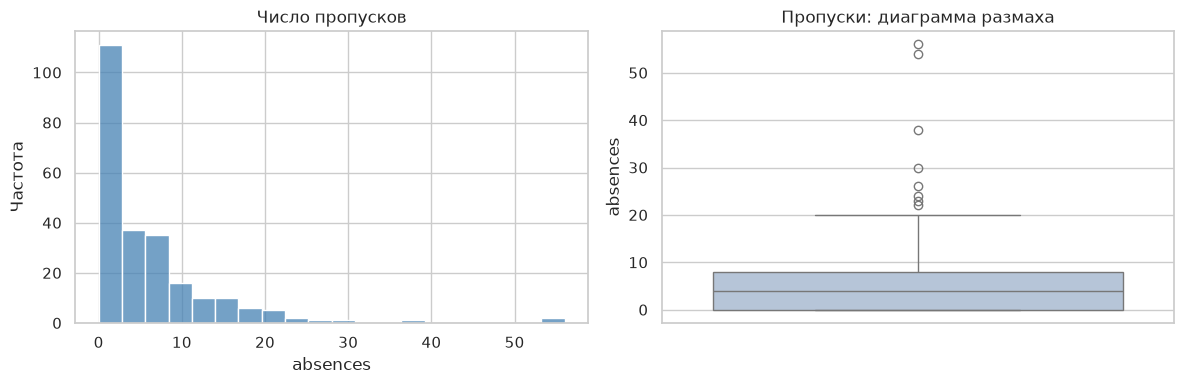

In [78]:
outlier_columns = ["age", "absences", "G1", "G2", "G3"]
outlier_rows = []
for col in outlier_columns:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (df[col] < lower) | (df[col] > upper)
    outlier_rows.append({"Признак": col, "Q1": q1, "Q3": q3,
                         "Нижняя граница": lower, "Верхняя граница": upper,
                         "Кандидатов в выбросы": int(mask.sum()),
                         "Min": df[col].min(), "Max": df[col].max()})
outlier_table = pd.DataFrame(outlier_rows)
display(outlier_table.round(2))
save_table(outlier_table, "iqr_outliers.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["absences"], bins=20, ax=axes[0], color="steelblue")
axes[0].set(title="Число пропусков", xlabel="absences", ylabel="Частота")
sns.boxplot(y=df["absences"], ax=axes[1], color="lightsteelblue")
axes[1].set(title="Пропуски: диаграмма размаха", ylabel="absences")
plt.tight_layout()
plt.savefig(figures_dir / "absences_outliers.png", dpi=200, bbox_inches="tight")
plt.show()

### Описательная статистика и распределения признаков

Для количественных переменных выводим среднее, медиану, стандартное отклонение, квартили. Порядковые признаки не трактуем как точные часы или расстояния: коды категорий обозначают интервалы или градации.

,Признак,count,mean,std,min,25%,50%,75%,max
0,age,237.0,16.71,1.25,15.0,16.0,17.0,18.0,22.0
1,Medu,237.0,2.73,1.12,0.0,2.0,3.0,4.0,4.0
2,Fedu,237.0,2.54,1.13,0.0,2.0,3.0,4.0,4.0
3,traveltime,237.0,1.50,0.70,1.0,1.0,1.0,2.0,4.0
4,studytime,237.0,2.01,0.83,1.0,1.0,2.0,2.0,4.0
5,failures,237.0,0.32,0.78,0.0,0.0,0.0,0.0,3.0
6,famrel,237.0,3.92,0.96,1.0,3.0,4.0,5.0,5.0
7,freetime,237.0,3.23,0.98,1.0,3.0,3.0,4.0,5.0
8,goout,237.0,3.06,1.12,1.0,2.0,3.0,4.0,5.0
9,Dalc,237.0,1.46,0.87,1.0,1.0,1.0,2.0,5.0


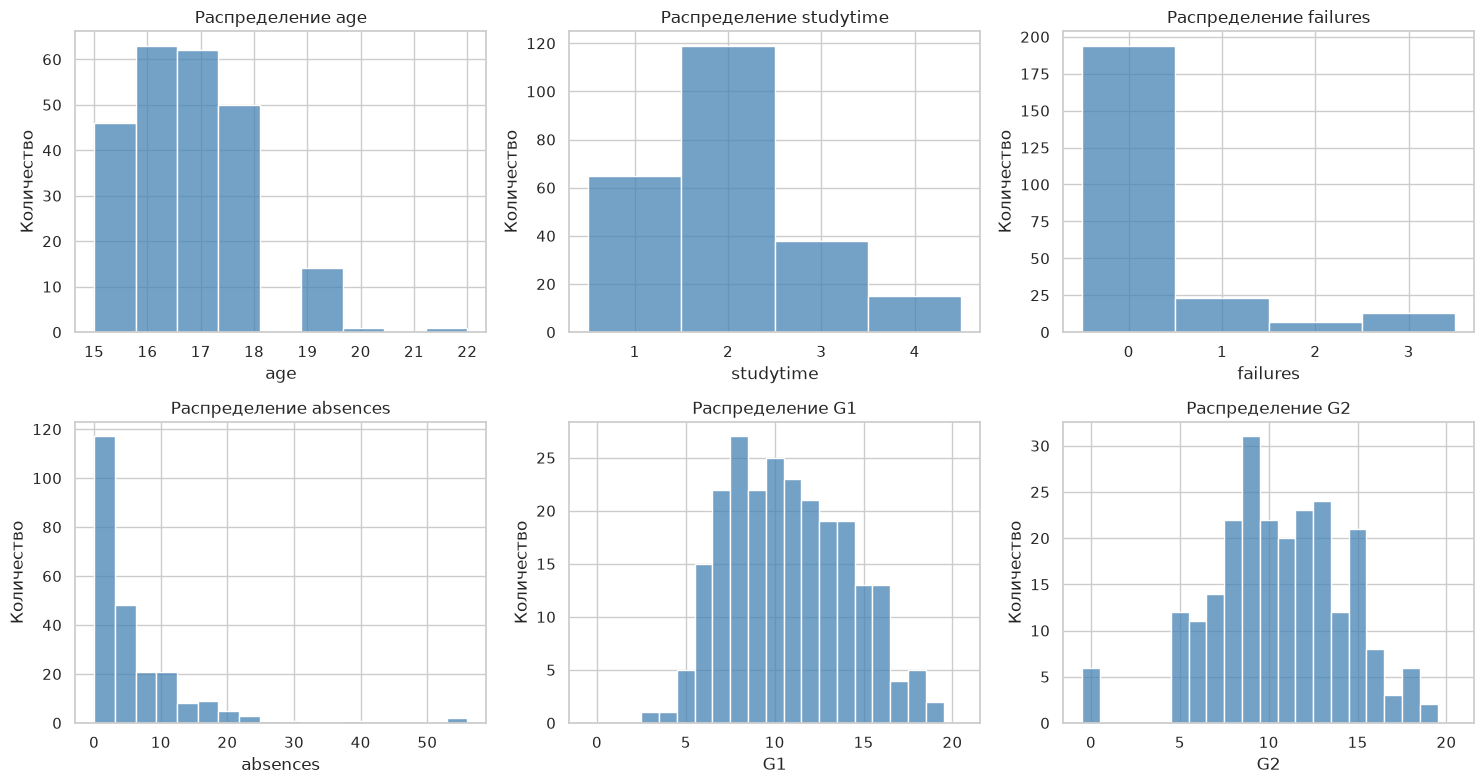

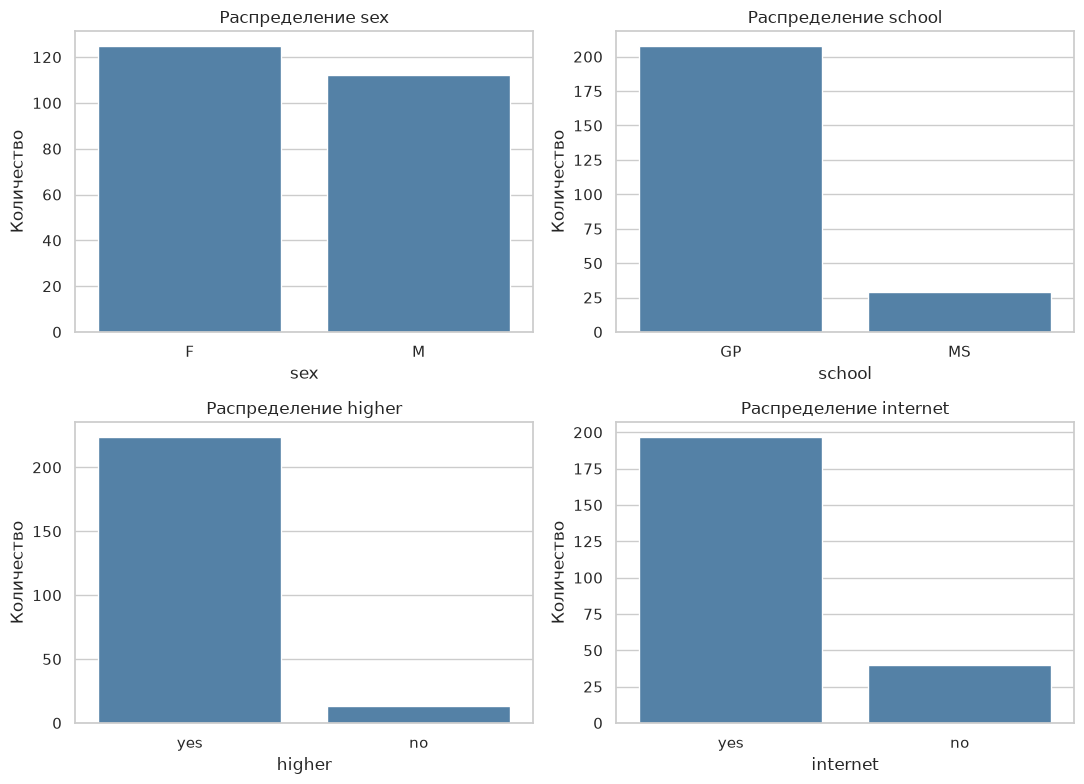

In [79]:
numeric_columns = df.select_dtypes(include="number").columns.tolist()
summary_stats = df[numeric_columns].describe().T.reset_index().rename(columns={"index": "Признак"})
display(summary_stats.round(2))
save_table(summary_stats, "numeric_descriptives.csv")

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
feature_bins = {
    "age": 9, "studytime": [0.5, 1.5, 2.5, 3.5, 4.5],
    "failures": [-0.5, 0.5, 1.5, 2.5, 3.5],
    "absences": 18, "G1": np.arange(-0.5, 21.5, 1),
    "G2": np.arange(-0.5, 21.5, 1),
}
for ax, (col, bins) in zip(axes.flat, feature_bins.items()):
    sns.histplot(df[col], bins=bins, ax=ax, color="steelblue")
    ax.set(title=f"Распределение {col}", xlabel=col, ylabel="Количество")
plt.tight_layout()
plt.savefig(figures_dir / "numeric_distributions.png", dpi=200, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.flat, ["sex", "school", "higher", "internet"]):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=ax, color="steelblue")
    ax.set(title=f"Распределение {col}", xlabel=col, ylabel="Количество")
plt.tight_layout()
plt.savefig(figures_dir / "categorical_distributions.png", dpi=200, bbox_inches="tight")
plt.show()

### Связи признаков с `G3` и между собой

Для **числовых** признаков вычисляем коэффициенты Пирсона (линейная зависимость) и Спирмена (монотонная зависимость). Корреляция не доказывает причинно-следственную связь. Показатели `G1` и `G2` особенно важны: они доступны не во всякий момент прогнозирования.

,Признак,Пирсон с G3,Спирмен с G3
14,G2,0.907,0.960
13,G1,0.836,0.900
5,failures,-0.365,-0.354
2,Fedu,0.245,0.263
1,Medu,0.241,0.243
0,age,-0.209,-0.204
8,goout,-0.145,-0.169
10,Walc,-0.085,-0.135
4,studytime,0.110,0.126
3,traveltime,-0.108,-0.122


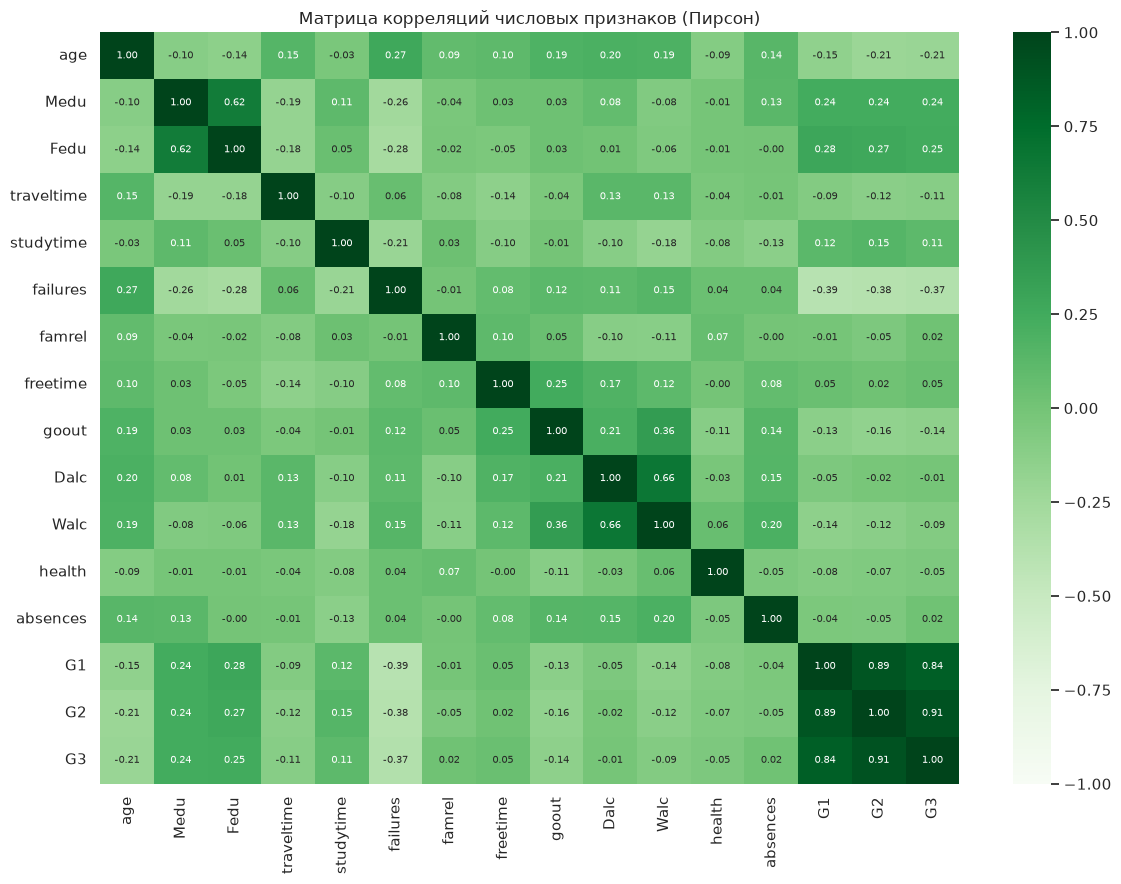

In [80]:
pearson_corr = df[numeric_columns].corr(method="pearson")
spearman_corr = df[numeric_columns].corr(method="spearman")

corr_target = pd.DataFrame({
    "Признак": [c for c in numeric_columns if c != "G3"],
    "Пирсон с G3": [pearson_corr.loc[c, "G3"] for c in numeric_columns if c != "G3"],
    "Спирмен с G3": [spearman_corr.loc[c, "G3"] for c in numeric_columns if c != "G3"],
}).sort_values("Спирмен с G3", key=lambda s: s.abs(), ascending=False)
display(corr_target.round(3))
save_table(corr_target, "g3_correlations.csv")

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(pearson_corr, cmap="Greens", vmin=-1, vmax=1,
            center=0, annot=True, fmt=".2f", annot_kws={"fontsize":7}, ax=ax)
ax.set_title("Матрица корреляций числовых признаков (Пирсон)")
plt.tight_layout()
plt.savefig(figures_dir / "correlation_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

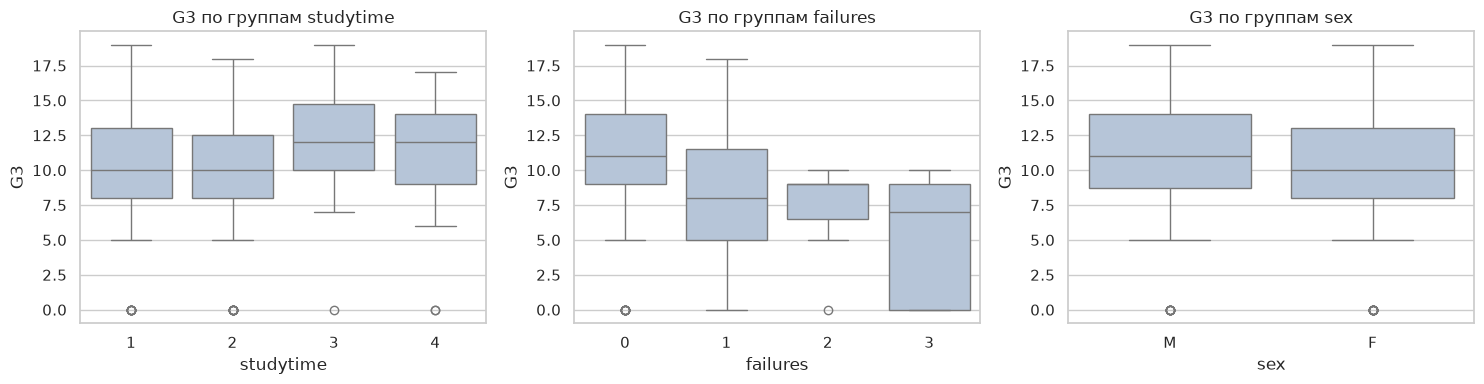

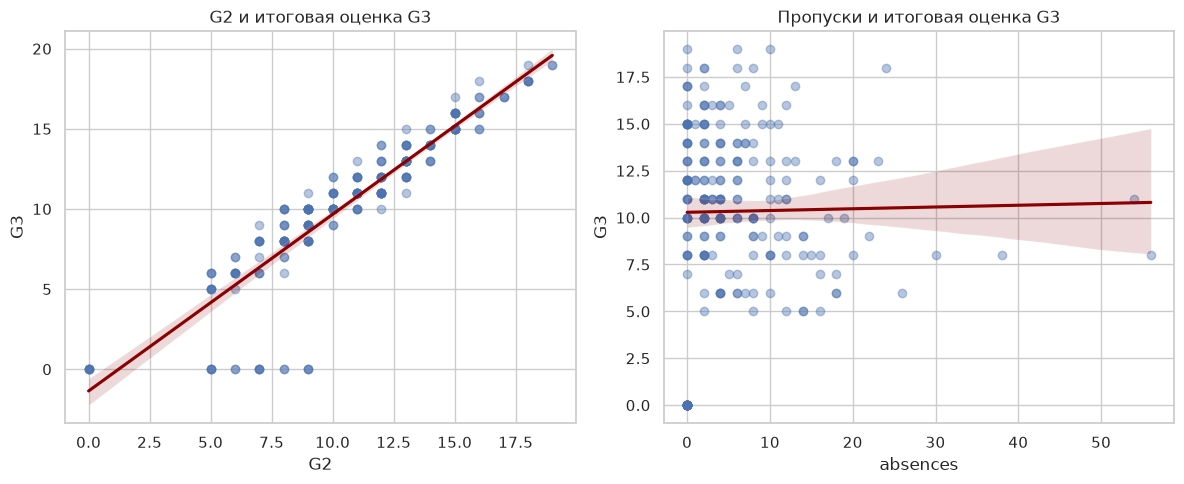

In [81]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["studytime", "failures", "sex"]):
    sns.boxplot(data=df, x=col, y="G3", ax=ax, color="lightsteelblue")
    ax.set(title=f"G3 по группам {col}", xlabel=col, ylabel="G3")
plt.tight_layout()
plt.savefig(figures_dir / "g3_by_groups.png", dpi=200, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.regplot(data=df, x="G2", y="G3", ax=axes[0],
            scatter_kws={"alpha":0.40}, line_kws={"color":"darkred"})
axes[0].set(title="G2 и итоговая оценка G3")
sns.regplot(data=df, x="absences", y="G3", ax=axes[1],
            scatter_kws={"alpha":0.4}, line_kws={"color":"darkred"})
axes[1].set(title="Пропуски и итоговая оценка G3")
plt.tight_layout()
plt.savefig(figures_dir / "grade_and_absences_relation.png", dpi=200, bbox_inches="tight")
plt.show()

### Проверка трёх предметных гипотез

**Гипотеза H1.** Большее число прошлых неудач (`failures`) связано с более низкой оценкой `G3`.

**Гипотеза H2.** Более высокая категория времени учёбы (`studytime`) связана с более высокой `G3`.

**Гипотеза H3.** Большее количество пропусков (`absences`) связано с более низкой `G3`.

Для каждой гипотезы используем коэффициент Спирмена с двухсторонним p-value. Порог 0,05 — ориентир для **разведочного** исследования (без поправки на множественные проверки); знак коэффициента показывает направление связи. Нельзя интерпретировать корреляцию как причинное влияние.

In [82]:
hypotheses = [
    ("H1", "failures", "отрицательная"),
    ("H2", "studytime", "положительная"),
    ("H3", "absences", "отрицательная"),
]

hypothesis_results = []
for label, feature, expected_direction in hypotheses:
    rho, p = stats.spearmanr(df[feature], df["G3"], nan_policy="omit")
    observed_direction = ("положительная" if rho > 0 else
                          "отрицательная" if rho < 0 else "отсутствует")
    # Двусторонняя проверка значимости + проверка заранее заданного направления.
    supported = (p < 0.05) and (observed_direction == expected_direction)
    verdict = ("Есть статистические свидетельства связи в ожидаемом направлении"
               if supported else "Убедительных свидетельств связи в ожидаемом направлении нет")
    hypothesis_results.append({
        "Гипотеза": label, "Фактор": feature, "Ожидалось": expected_direction,
        "Spearman rho": float(rho), "p-value": float(p), "Вывод": verdict,
    })
hypothesis_table = pd.DataFrame(hypothesis_results)
display(hypothesis_table.round(5))
save_table(hypothesis_table, "hypotheses_results.csv")

print("Группы по failures:")
display(df.groupby("failures")["G3"].agg(["count", "mean", "median"]).round(2))
print("Группы по studytime:")
display(df.groupby("studytime")["G3"].agg(["count", "mean", "median"]).round(2))

,Гипотеза,Фактор,Ожидалось,Spearman rho,p-value,Вывод
0,H1,failures,отрицательная,-0.35417,0.00000,Есть статистические свидетельства связи в ожид...
1,H2,studytime,положительная,0.12622,0.05229,Убедительных свидетельств связи в ожидаемом на...
2,H3,absences,отрицательная,-0.00396,0.95161,Убедительных свидетельств связи в ожидаемом на...


Группы по failures:


,count,mean,median
failures,,,
0,194,11.09,11.0
1,23,7.87,8.0
2,7,7.14,9.0
3,13,5.15,7.0


Группы по studytime:


,count,mean,median
studytime,,,
1,65,10.03,10.0
2,119,9.88,10.0
3,38,12.21,12.0
4,15,10.53,12.0


,count,mean,median
has_failures,,,
Были,43,6.93,8.0
Не было,194,11.09,11.0


Манна–Уитни для групп с/без неудач: U = 6316.5, p = 1.1908e-07


,count,mean,median
abs_group,,,
0,66,8.52,10.0
1–5,82,11.41,11.0
6–10,48,11.40,11.0
11–20,33,9.82,9.0
21+,8,10.12,8.5


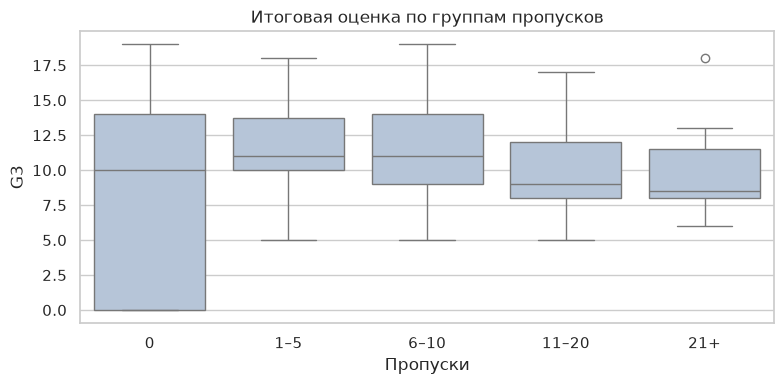

In [83]:
# Дополнительное сравнение: есть ли хотя бы одна прежняя учебная неудача.
fail_group = df.assign(has_failures=np.where(df["failures"] > 0, "Были", "Не было"))
fail_comparison = fail_group.groupby("has_failures")["G3"].agg(["count", "mean", "median"])
u_stat, u_p = stats.mannwhitneyu(
    df.loc[df["failures"] == 0, "G3"],
    df.loc[df["failures"] > 0, "G3"], alternative="two-sided"
)
display(fail_comparison.round(2))
print(f"Манна–Уитни для групп с/без неудач: U = {u_stat:.1f}, p = {u_p:.5g}")

# Наглядные интервалы для числа пропусков; не используем G3 для построения интервалов.
absence_bounds = [-0.1, 0, 5, 10, 20, np.inf]
absence_labels = ["0", "1–5", "6–10", "11–20", "21+"]
abs_group = df.assign(abs_group=pd.cut(df["absences"], bins=absence_bounds, labels=absence_labels))
absences_by_group = abs_group.groupby("abs_group", observed=False)["G3"].agg(["count", "mean", "median"])
display(absences_by_group.round(2))
save_table(absences_by_group.reset_index(), "absences_grouped_g3.csv")

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=abs_group, x="abs_group", y="G3", order=absence_labels,
            ax=ax, color="lightsteelblue")
ax.set(title="Итоговая оценка по группам пропусков", xlabel="Пропуски", ylabel="G3")
plt.tight_layout()
plt.savefig(figures_dir / "g3_by_absences_groups.png", dpi=200, bbox_inches="tight")
plt.show()

### Доступность признаков и риск утечки информации

Мы должны различать **два момента предсказания**:

- **Ранний прогноз:** до выставления `G1`/`G2`. Эти оценки и целевая `G3` запрещены во входных признаках.
- **Поздний прогноз:** после второго контрольного периода. `G1` и `G2` использовать можно, если они реально известны, но `G3` по-прежнему недоступна до конца периода.

В учебных `batch_XX.csv` поле `G3` сохранено, потому что записи исторические. При имитации предсказания оно **исключается из входа** и используется исключительно для отложенной оценки модели. Наличие `G3` в CSV не означает, что в реальной системе оно известно в момент прогноза.

In [84]:
availability_plan = pd.DataFrame([
    ["school, sex, age, address, Medu, Fedu и др.", "до периода", "да", "да", "Базовые сведения"],
    ["studytime, failures, absences", "при заполнении анкеты / накоплении", "по фактической доступности", "да", "Не использовать будущие сведения о пропусках"],
    ["G1", "после 1-го периода", "нет", "да", "Ранний прогноз не должен видеть G1"],
    ["G2", "после 2-го периода", "нет", "да", "Ранний прогноз не должен видеть G2"],
    ["G3", "после окончания обучения", "нет", "нет", "Только целевая переменная"],
], columns=["Признаки", "Когда становятся известны", "Ранний прогноз", "Поздний прогноз", "Ограничение"])
display(availability_plan)
save_table(availability_plan, "feature_availability.csv")

# Два списка признаков для проектирования, без обучения моделей.
feature_set_early = [c for c in df.columns if c not in {"G1", "G2", "G3"}]
feature_set_late = [c for c in df.columns if c != "G3"]
print("Ранний сценарий:", len(feature_set_early), "исходных признаков")
print("Поздний сценарий:", len(feature_set_late), "исходных признаков")

,Признаки,Когда становятся известны,Ранний прогноз,Поздний прогноз,Ограничение
0,"school, sex, age, address, Medu, Fedu и др.",до периода,да,да,Базовые сведения
1,"studytime, failures, absences",при заполнении анкеты / накоплении,по фактической доступности,да,Не использовать будущие сведения о пропусках
2,G1,после 1-го периода,нет,да,Ранний прогноз не должен видеть G1
3,G2,после 2-го периода,нет,да,Ранний прогноз не должен видеть G2
4,G3,после окончания обучения,нет,нет,Только целевая переменная


Ранний сценарий: 30 исходных признаков
Поздний сценарий: 32 исходных признаков


### Вывод по подразделу

Нижеследующий вывод **формируется по вычисленным значениям**, поэтому не зависит от ручного переписывания результатов. Значимость связей следует понимать как статистическую ассоциацию, не как доказательство причинности.

In [85]:
results_by_factor = hypothesis_table.set_index("Фактор")
def short_hypothesis(factor):
    r = results_by_factor.loc[factor]
    return (f"ρ={r['Spearman rho']:.3f}; p={r['p-value']:.3g}. " + r["Вывод"] + ".")

eda_conclusion = (
    f"В начальной части набора содержится {len(df)} записей и {df.shape[1]} столбца. "
    f"Пропусков: {int(df.isna().sum().sum())}; полных дубликатов: {int(df.duplicated().sum())}. "
    f"Средняя итоговая оценка G3 = {df['G3'].mean():.2f}, "
    f"доля G3 < 10 = {df['G3'].lt(10).mean():.1%}.\n\n"
    f"H1 (предыдущие неудачи): {short_hypothesis('failures')}\n\n"
    f"H2 (время самостоятельной учёбы): {short_hypothesis('studytime')}\n\n"
    f"H3 (пропуски): {short_hypothesis('absences')}\n\n"
    "Для дальнейшего проектирования необходимы проверки диапазонов/категорий, "
    "явная обработка пропусков и сохранение одинаковых преобразований при обучении и прогнозировании. "
    "Нельзя использовать G3 как входной признак; G1/G2 допустимы лишь для позднего сценария."
)
display(Markdown(eda_conclusion))
(tables_dir / "conclusion_2_2.txt").write_text(eda_conclusion, encoding="utf-8")

В начальной части набора содержится 237 записей и 33 столбца. Пропусков: 0; полных дубликатов: 0. Средняя итоговая оценка G3 = 10.34, доля G3 < 10 = 34.2%.

H1 (предыдущие неудачи): ρ=-0.354; p=2.07e-08. Есть статистические свидетельства связи в ожидаемом направлении.

H2 (время самостоятельной учёбы): ρ=0.126; p=0.0523. Убедительных свидетельств связи в ожидаемом направлении нет.

H3 (пропуски): ρ=-0.004; p=0.952. Убедительных свидетельств связи в ожидаемом направлении нет.

Для дальнейшего проектирования необходимы проверки диапазонов/категорий, явная обработка пропусков и сохранение одинаковых преобразований при обучении и прогнозировании. Нельзя использовать G3 как входной признак; G1/G2 допустимы лишь для позднего сценария.

738

## Требования к качеству данных и ключевые показатели

Необходимо не менее **пяти проверяемых требований к качеству данных**, а также **3–5 KPI**, минимум два из которых опираются на модель. Здесь правила и показатели фиксируются как **проектные требования**; обучать новую модель в этой работе не требуется.

In [86]:
quality_requirements = pd.DataFrame([
    ["Q-01", "Обязательные поля", "Все обязательные признаки присутствуют", "Порцию отклонить, сообщить схему"],
    ["Q-02", "Обязательные признаки", "Не допускаются пропуски в age, studytime, failures", "Записи отправить на разбор"],
    ["Q-03", "G1, G2 и G3 (если присутствуют)", "Оценки — числа в диапазоне 0–20", "Некорректные записи изолировать"],
    ["Q-04", "studytime", "Значение — целое число от 1 до 4", "Некорректные записи изолировать"],
    ["Q-05", "failures", "Значение — целое число от 0 до 3", "Некорректные записи изолировать"],
    ["Q-06", "absences", "Значение — неотрицательное целое", "Отправить на проверку источника"],
    ["Q-07", "sex и категориальные поля", "Категории соответствуют справочнику", "Новые значения записать в лог, не кодировать наугад"],
    ["Q-08", "Совпадения строк", "Полные совпадения выявляются и регистрируются", "Не удалять автоматически без ID студента"],
], columns=["ID", "Признак(и)", "Требование", "Действие при нарушении"])
display(quality_requirements)
save_table(quality_requirements, "quality_requirements.csv")

# Проверяем главные правила на исследуемой исходной части.
quality_checks = pd.DataFrame([
    ["Q-01", len(missing_columns) == 0, len(missing_columns)],
    ["Q-02", df[["age", "studytime", "failures"]].notna().all().all(), int(df[["age", "studytime", "failures"]].isna().sum().sum())],
    ["Q-03", int(validation_summary.query("Признак in ['G1','G2','G3']")["Нарушений"].sum()) == 0,
     int(validation_summary.query("Признак in ['G1','G2','G3']")["Нарушений"].sum())],
    ["Q-04", int(validation_summary.loc[validation_summary["Признак"] == "studytime", "Нарушений"].sum()) == 0,
     int(validation_summary.loc[validation_summary["Признак"] == "studytime", "Нарушений"].sum())],
    ["Q-05", int(validation_summary.loc[validation_summary["Признак"] == "failures", "Нарушений"].sum()) == 0,
     int(validation_summary.loc[validation_summary["Признак"] == "failures", "Нарушений"].sum())],
    ["Q-06", ((df["absences"] >= 0) & (df["absences"] % 1 == 0)).all(),
     int(((df["absences"] < 0) | (df["absences"] % 1 != 0)).sum())],
    ["Q-07", (invalid_categories["Неизвестных значений"] == 0).all(), int(invalid_categories["Неизвестных значений"].sum())],
    ["Q-08", True, int(df.duplicated().sum())], # журналируем; дубликаты не запрещены при отсутствии ID
], columns=["ID", "Требование пройдено", "Нарушений / совпадений"])
display(quality_checks)
save_table(quality_checks, "quality_checks_initial.csv")

,ID,Признак(и),Требование,Действие при нарушении
0,Q-01,Обязательные поля,Все обязательные признаки присутствуют,"Порцию отклонить, сообщить схему"
1,Q-02,Обязательные признаки,"Не допускаются пропуски в age, studytime, fail...",Записи отправить на разбор
2,Q-03,"G1, G2 и G3 (если присутствуют)",Оценки — числа в диапазоне 0–20,Некорректные записи изолировать
3,Q-04,studytime,Значение — целое число от 1 до 4,Некорректные записи изолировать
4,Q-05,failures,Значение — целое число от 0 до 3,Некорректные записи изолировать
5,Q-06,absences,Значение — неотрицательное целое,Отправить на проверку источника
6,Q-07,sex и категориальные поля,Категории соответствуют справочнику,"Новые значения записать в лог, не кодировать н..."
7,Q-08,Совпадения строк,Полные совпадения выявляются и регистрируются,Не удалять автоматически без ID студента


,ID,Требование пройдено,Нарушений / совпадений
0,Q-01,True,0
1,Q-02,True,0
2,Q-03,True,0
3,Q-04,True,0
4,Q-05,True,0
5,Q-06,True,0
6,Q-07,True,0
7,Q-08,True,0


In [87]:
# KPI, связанные с моделью, пока не рассчитываем: она не запускалась на порциях.
# Статус «—» означает проектный показатель, а не нулевое значение.
kpi_table = pd.DataFrame([
    ["KPI-01", "Средняя прогнозная оценка", "mean(model.predict(X_batch))", "Да", "Ожидаемый уровень успеваемости", "—"],
    ["KPI-02", "Доля студентов в зоне риска", "mean(model.predict(X_batch) < 10)", "Да", "Кому требуется дополнительное внимание", "—"],
    ["KPI-03", "Размер поступившей порции", "len(batch)", "Нет", "Контроль объёма поступлений", len(df)],
    ["KPI-04", "Доля известных итоговых оценок ниже 10", "mean(G3 < 10) по размеченным записям", "Нет", "Контроль фактической успеваемости", round(df["G3"].lt(10).mean(), 4)],
    ["KPI-05", "Доля записей без нарушений обязательных полей", "число корректных строк / общее число строк", "Нет", "Контроль качества источника", round(df[["age", "studytime", "failures"]].notna().all(axis=1).mean(), 4)],
], columns=["ID", "Показатель", "Формула", "Использует модель", "Помогает решить", "Значение на исходных данных"])
display(kpi_table)
save_table(kpi_table, "kpi_plan.csv")

,ID,Показатель,Формула,Использует модель,Помогает решить,Значение на исходных данных
0,KPI-01,Средняя прогнозная оценка,mean(model.predict(X_batch)),Да,Ожидаемый уровень успеваемости,—
1,KPI-02,Доля студентов в зоне риска,mean(model.predict(X_batch) < 10),Да,Кому требуется дополнительное внимание,—
2,KPI-03,Размер поступившей порции,len(batch),Нет,Контроль объёма поступлений,237
3,KPI-04,Доля известных итоговых оценок ниже 10,mean(G3 < 10) по размеченным записям,Нет,Контроль фактической успеваемости,0.3418
4,KPI-05,Доля записей без нарушений обязательных полей,число корректных строк / общее число строк,Нет,Контроль качества источника,1.0


**Вывод** Правила `Q-01`–`Q-08` превращают наблюдения EDA в проверяемые ограничения. KPI-01 и KPI-02 **проектируются**, но их нельзя выдавать за измеренные величины до запуска модели на очередной порции. Для KPI-03–KPI-05 показаны примеры расчётов по исходным данным.

## Требования к системе

Функциональные требования описывают действия программы. Нефункциональные — измеримые ограничения производительности, воспроизводимости и надёжности. Указанные целевые пороги **проектные**: их ещё предстоит проверить при реализации.

In [88]:
system_requirements = pd.DataFrame([
    ["F-01", "Принимает входную CSV-порцию и проверяет обязательные поля", "Функциональное", "Импорт тестовой порции"],
    ["F-02", "Выполняет проверки Q-01–Q-08 и создаёт отчёт о нарушениях", "Функциональное", "Тест на некорректных строках"],
    ["F-03", "Использует одинаковую схему очистки и преобразования признаков", "Функциональное", "Сравнение выходов обучения и инференса"],
    ["F-04", "Выдаёт прогноз G3 для доступного сценария признаков", "Функциональное", "Запрос к модулю прогнозирования"],
    ["F-05", "После обработки порции пересчитывает 3–5 KPI", "Функциональное", "Сравнение расчётов с контрольным примером"],
    ["F-06", "Позволяет получить прогноз по запросу пользователя", "Функциональное", "Тестовый запрос к API"],
    ["F-07", "Предоставляет просмотр показателей и их динамики", "Функциональное", "Демонстрация аналитической панели"],
    ["N-01", "Обрабатывает порцию из 1000 строк не более чем за 30 секунд", "Нефункциональное", "Замер времени на целевом компьютере"],
    ["N-02", "Повторный запуск на тех же данных/параметрах даёт идентичные результаты", "Нефункциональное", "Сравнение контрольных сумм выходов"],
    ["N-03", "100% отклонённых строк отражаются в журнале ошибок", "Нефункциональное", "Сверка журнала и ошибочных записей"],
    ["Q-01–Q-08", "Соблюдаются правила качества из раздела 2.3", "Качество данных", "Автоматизированные валидационные проверки"],
], columns=["ID", "Требование", "Группа", "Способ проверки"])
display(system_requirements)
save_table(system_requirements, "system_requirements.csv")

,ID,Требование,Группа,Способ проверки
0,F-01,Принимает входную CSV-порцию и проверяет обяза...,Функциональное,Импорт тестовой порции
1,F-02,Выполняет проверки Q-01–Q-08 и создаёт отчёт о...,Функциональное,Тест на некорректных строках
2,F-03,Использует одинаковую схему очистки и преобраз...,Функциональное,Сравнение выходов обучения и инференса
3,F-04,Выдаёт прогноз G3 для доступного сценария приз...,Функциональное,Запрос к модулю прогнозирования
4,F-05,После обработки порции пересчитывает 3–5 KPI,Функциональное,Сравнение расчётов с контрольным примером
5,F-06,Позволяет получить прогноз по запросу пользова...,Функциональное,Тестовый запрос к API
6,F-07,Предоставляет просмотр показателей и их динамики,Функциональное,Демонстрация аналитической панели
7,N-01,Обрабатывает порцию из 1000 строк не более чем...,Нефункциональное,Замер времени на целевом компьютере
8,N-02,Повторный запуск на тех же данных/параметрах д...,Нефункциональное,Сравнение контрольных сумм выходов
9,N-03,100% отклонённых строк отражаются в журнале ош...,Нефункциональное,Сверка журнала и ошибочных записей


**Вывод** Наиболее важны воспроизводимая обработка, предотвращение ошибочного прогноза на плохих данных и доступность обновлённых показателей. Показатели времени обработки и полноты логирования — критерии будущих испытаний, а не результаты текущего запуска.

## Архитектура системы: C4 и UML

Ниже — **проектная архитектура** с четырьмя схемами: контекст C4, контейнеры C4, варианты использования UML и последовательность UML. Сейчас реализованы отдельные модули анализа и обучения в `src/`; API, хранилище результатов, панель и процесс обновлений рассматриваются как будущие компоненты. Схемы создаются стандартным `matplotlib`, без установки новых библиотек.

In [89]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Ellipse, Rectangle, Polygon, Circle

def diagram_axis(title, figsize=(14, 8), xlim=(0, 14), ylim=(0, 9)):
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.axis("off")
    ax.set_title(title, fontsize=15, fontweight="bold", pad=16)
    return fig, ax

def box(ax, cx, cy, w, h, title, subtitle="", color="#EDF3FA", edge="#416483"):
    ax.add_patch(FancyBboxPatch((cx-w/2, cy-h/2), w, h,
                 boxstyle="round,pad=0.04,rounding_size=0.12",
                 facecolor=color, edgecolor=edge, linewidth=1.5))
    ax.text(cx, cy + (0.18 if subtitle else 0), title, ha="center", va="center",
            fontsize=10, fontweight="bold")
    if subtitle:
        ax.text(cx, cy-0.24, subtitle, ha="center", va="center", fontsize=8.5,
                color="#4B5563", linespacing=1.2)

def arrow(ax, x1, y1, x2, y2, label="", color="#475569", label_xy=None):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>",
                 mutation_scale=15, linewidth=1.5, color=color))
    if label:
        x, y = label_xy if label_xy else ((x1+x2)/2, (y1+y2)/2+0.15)
        ax.text(x, y, label, ha="center", va="center", fontsize=8.5, color=color)

def show_diagram(fig, filename):
    fig.savefig(figures_dir / filename, dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()


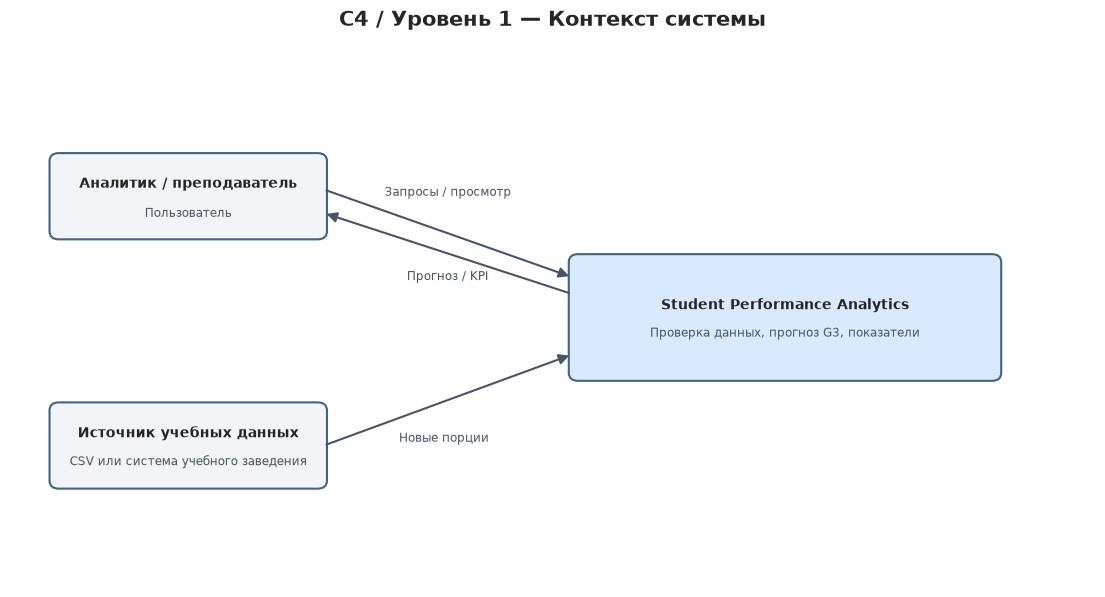

In [90]:
# C4 — Context: кто работает с системой и откуда поступают данные.
fig, ax = diagram_axis("C4 / Уровень 1 — Контекст системы", figsize=(14, 7), ylim=(0, 8))
box(ax, 2.3, 5.8, 3.5, 1.2, "Аналитик / преподаватель", "Пользователь", color="#F2F4F7")
box(ax, 2.3, 2.1, 3.5, 1.2, "Источник учебных данных", "CSV или система учебного заведения", color="#F2F4F7")
box(ax, 10.0, 4.0, 5.5, 1.8, "Student Performance Analytics", "Проверка данных, прогноз G3, показатели", color="#DAEAFE")
arrow(ax, 4.05, 5.9, 7.25, 4.6, "Запросы / просмотр", label_xy=(5.65, 5.85))
arrow(ax, 7.25, 4.35, 4.05, 5.55, "Прогноз / KPI", label_xy=(5.65, 4.60))
arrow(ax, 4.05, 2.1, 7.25, 3.45, "Новые порции", label_xy=(5.6, 2.20))
show_diagram(fig, "c4_context.png")


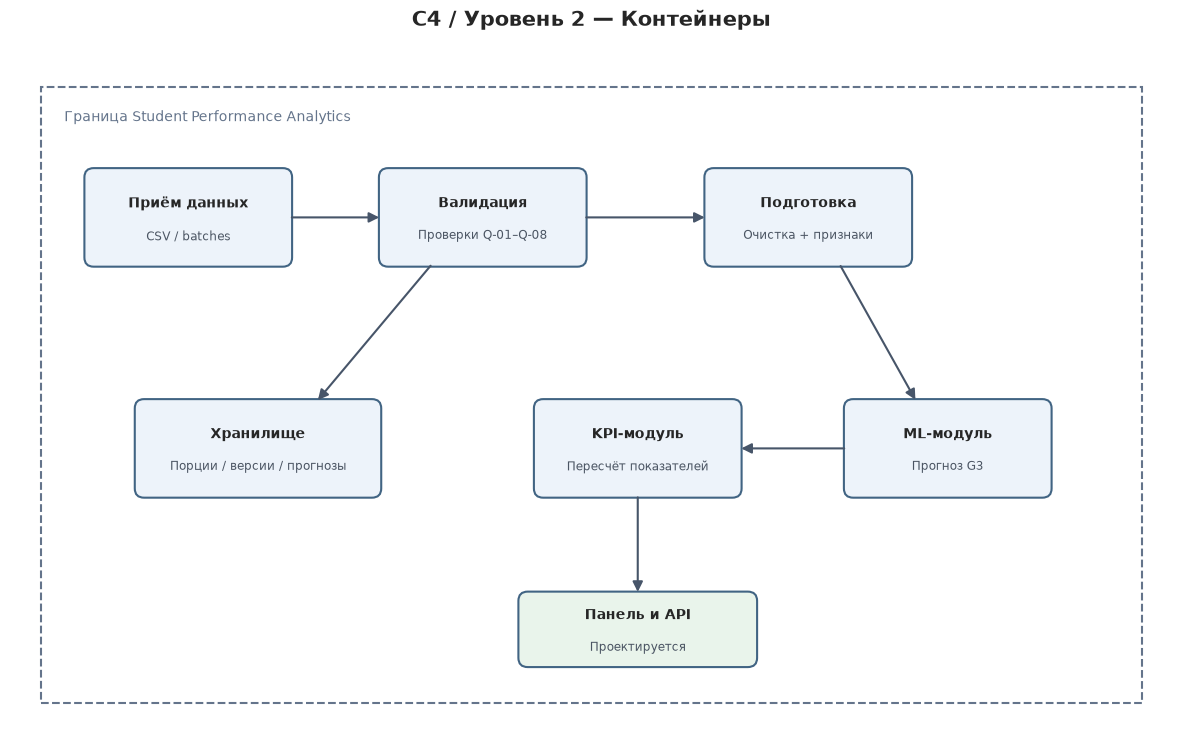

In [91]:
# C4 — Container: приложения и хранилища внутри системы.
fig, ax = diagram_axis("C4 / Уровень 2 — Контейнеры", figsize=(15, 9), xlim=(0, 15), ylim=(0, 9))
ax.add_patch(Rectangle((0.4, 0.5), 14.2, 8.0, fill=False, ls="--", lw=1.5, ec="#64748B"))
ax.text(0.7, 8.05, "Граница Student Performance Analytics", fontsize=10, color="#64748B")
box(ax, 2.3, 6.8, 2.6, 1.2, "Приём данных", "CSV / batches")
box(ax, 6.1, 6.8, 2.6, 1.2, "Валидация", "Проверки Q-01–Q-08")
box(ax, 10.3, 6.8, 2.6, 1.2, "Подготовка", "Очистка + признаки")
box(ax, 12.1, 3.8, 2.6, 1.2, "ML-модуль", "Прогноз G3")
box(ax, 8.1, 3.8, 2.6, 1.2, "KPI-модуль", "Пересчёт показателей")
box(ax, 3.2, 3.8, 3.1, 1.2, "Хранилище", "Порции / версии / прогнозы")
box(ax, 8.1, 1.45, 3.0, 0.9, "Панель и API", "Проектируется", color="#E9F4EB")
arrow(ax, 3.6, 6.8, 4.8, 6.8)
arrow(ax, 7.4, 6.8, 9.0, 6.8)
arrow(ax, 10.7, 6.2, 11.7, 4.4)
arrow(ax, 10.8, 3.8, 9.4, 3.8)
arrow(ax, 5.45, 6.2, 3.95, 4.4)
arrow(ax, 8.1, 3.2, 8.1, 1.9)
show_diagram(fig, "c4_containers.png")


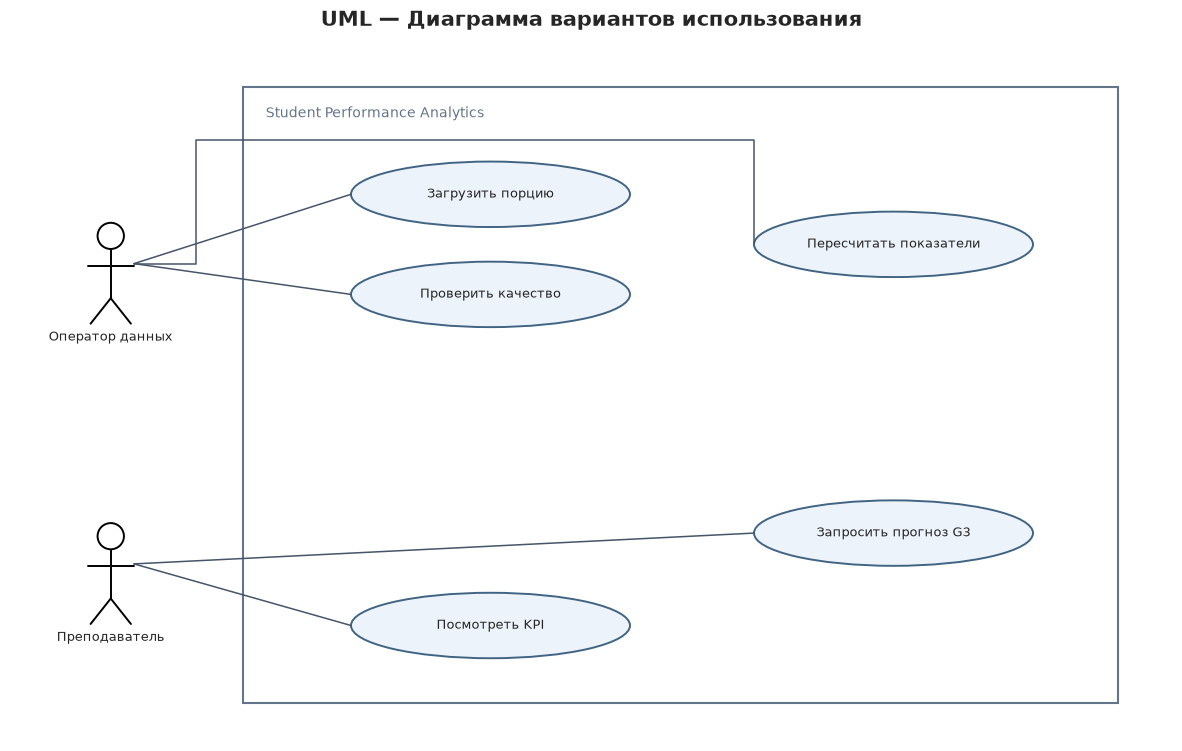

In [92]:
# UML Use Case — два действующих лица и основные сценарии.
fig, ax = diagram_axis("UML — Диаграмма вариантов использования", figsize=(15, 9), xlim=(0, 15), ylim=(0, 9))
ax.add_patch(Rectangle((3.0, 0.5), 11.3, 8.0, fill=False, lw=1.5, ec="#64748B"))
ax.text(3.3, 8.1, "Student Performance Analytics", fontsize=10, color="#64748B")

def actor(ax, x, y, name):
    ax.add_patch(Circle((x, y+0.36), 0.17, facecolor="none", edgecolor="black", lw=1.4))
    ax.plot([x, x], [y+0.18, y-0.45], color="black", lw=1.4)
    ax.plot([x-0.3, x+0.3], [y-0.03, y-0.03], color="black", lw=1.4)
    ax.plot([x, x-0.26], [y-0.45, y-0.78], color="black", lw=1.4)
    ax.plot([x, x+0.26], [y-0.45, y-0.78], color="black", lw=1.4)
    ax.text(x, y-1.0, name, fontsize=9, ha="center")

def case(ax, x, y, label):
    ax.add_patch(Ellipse((x, y), 3.6, 0.85, facecolor="#EDF3FA", edgecolor="#416483", lw=1.4))
    ax.text(x, y, label, ha="center", va="center", fontsize=9)

def assoc(ax, points):
    xs, ys = zip(*points)
    ax.plot(xs, ys, lw=1.1, color="#475569")

actor(ax, 1.3, 6.2, "Оператор данных")
actor(ax, 1.3, 2.3, "Преподаватель")
case(ax, 6.2, 7.1, "Загрузить порцию")
case(ax, 6.2, 5.8, "Проверить качество")
case(ax, 11.4, 6.45, "Пересчитать показатели")
case(ax, 11.4, 2.7, "Запросить прогноз G3")
case(ax, 6.2, 1.5, "Посмотреть KPI")
assoc(ax, [(1.6, 6.2), (4.4, 7.1)])
assoc(ax, [(1.6, 6.2), (4.4, 5.8)])
assoc(ax, [(1.6, 6.2), (2.4, 6.2), (2.4, 7.8), (9.6, 7.8), (9.6, 6.45)])
assoc(ax, [(1.6, 2.3), (4.4, 1.5)])
assoc(ax, [(1.6, 2.3), (9.6, 2.7)])
show_diagram(fig, "uml_use_cases.png")


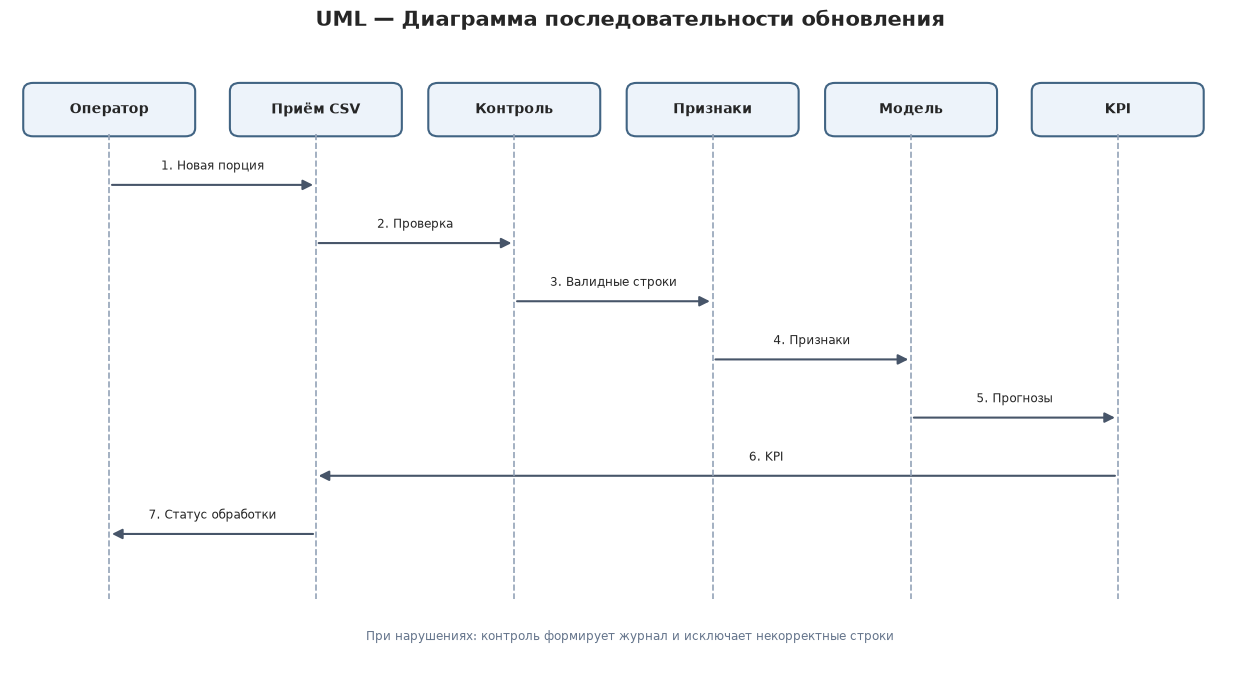

In [93]:
# UML Sequence — основной сценарий поступления порции.
fig, ax = diagram_axis("UML — Диаграмма последовательности обновления", figsize=(16, 8), xlim=(0, 15), ylim=(0, 9))
participants = ["Оператор", "Приём CSV", "Контроль", "Признаки", "Модель", "KPI"]
xs = [1.2, 3.7, 6.1, 8.5, 10.9, 13.4]
for x, name in zip(xs, participants):
    box(ax, x, 8.1, 2.0, 0.7, name, color="#EDF3FA")
    ax.plot([x, x], [7.75, 0.95], color="#94A3B8", ls="--", lw=1.2)

messages = [
    (0, 1, "1. Новая порция", 7.0),
    (1, 2, "2. Проверка", 6.15),
    (2, 3, "3. Валидные строки", 5.3),
    (3, 4, "4. Признаки", 4.45),
    (4, 5, "5. Прогнозы", 3.6),
    (5, 1, "6. KPI", 2.75),
    (1, 0, "7. Статус обработки", 1.9),
]
for src, dst, msg, y in messages:
    arrow(ax, xs[src], y, xs[dst], y)
    label_x = (xs[src]+xs[dst])/2 + (0.6 if msg == "6. KPI" else 0)
    ax.text(label_x, y+0.18, msg, ha="center", va="bottom", fontsize=8.5)
ax.text(7.5, 0.35, "При нарушениях: контроль формирует журнал и исключает некорректные строки",
        ha="center", fontsize=8.5, color="#64748B")
show_diagram(fig, "uml_sequence.png")


**Вывод** Контекст показывает пользователей и внешний источник, контейнеры — логические части будущего решения, UML — пользовательские сценарии и порядок обмена сообщениями. Наличие схемы **не означает**, что панель, API и модуль обновлений уже реализованы.

## Пайплайн и план инжиниринга признаков

В этом подразделе пайплайн **проектируется**: загрузка → проверка качества → очистка → формирование признаков → сохранение → применение обученной модели → обновление показателей. Для обучения отдельно предусматриваются разбиение выборки, `fit` преобразователей и обучение модели. Для новой порции допускается только `transform` уже обученными преобразователями — это предотвращает утечку информации и несоответствие категорий.

In [94]:
pipeline_steps = pd.DataFrame([
    ["01", "Загрузка", "CSV initial/batch", "Чтение, контроль схемы", "Таблица исходных данных", "Оба"],
    ["02", "Проверка качества", "Исходная таблица", "Правила Q-01–Q-08, журнал", "Проверенные записи", "Оба"],
    ["03", "Очистка", "Проверенные записи", "Обработка допустимых пропусков и аномалий", "Чистые данные", "Оба"],
    ["04", "Новые признаки", "Чистые данные", "Генерация признаков из таблицы 2.5", "Таблица признаков", "Оба"],
    ["05", "Кодирование и масштабирование", "Таблица признаков", "fit на train; transform на новых данных", "Матрица X", "Оба (fit — только train)"],
    ["06", "Обучение модели", "X_train, y_train", "Обучение/проверка качества модели", "Сохранённая модель", "Только обучение"],
    ["07", "Прогноз", "X_batch + сохранённая модель", "predict без использования G3", "Предсказанные G3", "Только новая порция"],
    ["08", "Сохранение", "Порция, отчёт качества, признаки", "Сохранение версий и результатов", "Артефакты порции", "Оба"],
    ["09", "KPI", "Прогнозы и метаданные", "Пересчёт 3–5 показателей", "Обновлённые KPI", "Только новая порция"],
], columns=["Шаг", "Этап", "Вход", "Действие", "Выход", "Применение"])
display(pipeline_steps)
save_table(pipeline_steps, "pipeline_steps.csv")

,Шаг,Этап,Вход,Действие,Выход,Применение
0,01,Загрузка,CSV initial/batch,"Чтение, контроль схемы",Таблица исходных данных,Оба
1,02,Проверка качества,Исходная таблица,"Правила Q-01–Q-08, журнал",Проверенные записи,Оба
2,03,Очистка,Проверенные записи,Обработка допустимых пропусков и аномалий,Чистые данные,Оба
3,04,Новые признаки,Чистые данные,Генерация признаков из таблицы 2.5,Таблица признаков,Оба
4,05,Кодирование и масштабирование,Таблица признаков,fit на train; transform на новых данных,Матрица X,Оба (fit — только train)
5,06,Обучение модели,"X_train, y_train",Обучение/проверка качества модели,Сохранённая модель,Только обучение
6,07,Прогноз,X_batch + сохранённая модель,predict без использования G3,Предсказанные G3,Только новая порция
7,08,Сохранение,"Порция, отчёт качества, признаки",Сохранение версий и результатов,Артефакты порции,Оба
8,09,KPI,Прогнозы и метаданные,Пересчёт 3–5 показателей,Обновлённые KPI,Только новая порция


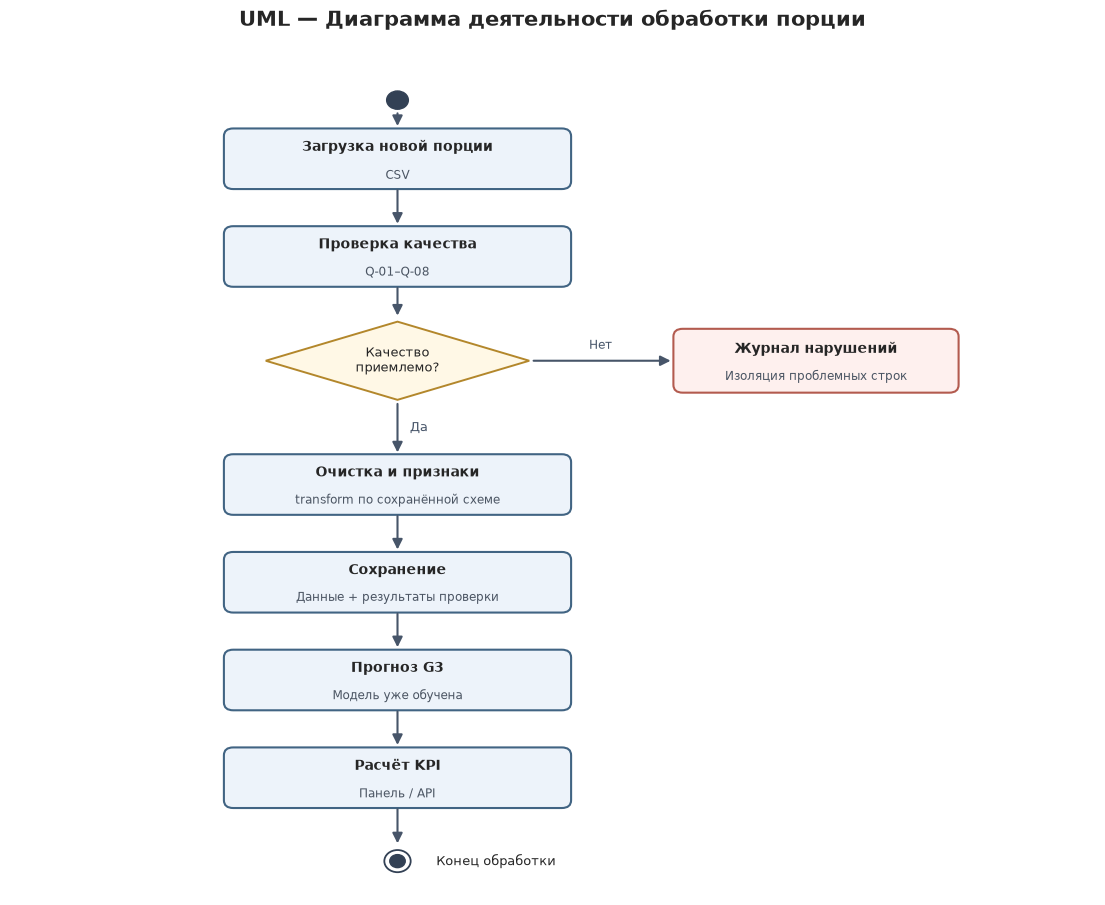

In [95]:
# Схема деятельности UML: обработка одной новой порции; наличие ошибочных строк
# приводит к их регистрации и отправке на проверку.
fig, ax = diagram_axis("UML — Диаграмма деятельности обработки порции", figsize=(14, 11), xlim=(0, 14), ylim=(0, 13))
ax.add_patch(Circle((5.0, 12.2), 0.14, color="#334155"))
steps = [
    (11.3, "Загрузка новой порции", "CSV"),
    (9.8, "Проверка качества", "Q-01–Q-08"),
    (6.3, "Очистка и признаки", "transform по сохранённой схеме"),
    (4.8, "Сохранение", "Данные + результаты проверки"),
    (3.3, "Прогноз G3", "Модель уже обучена"),
    (1.8, "Расчёт KPI", "Панель / API"),
]
for y, title, subtitle in steps:
    box(ax, 5.0, y, 4.4, 0.85, title, subtitle)
arrow(ax, 5.0, 12.04, 5.0, 11.76)
arrow(ax, 5.0, 10.86, 5.0, 10.26)
arrow(ax, 5.0, 9.36, 5.0, 8.85)
ax.add_patch(Polygon([[5.0, 8.8], [6.7, 8.2], [5.0, 7.6], [3.3, 8.2]],
             facecolor="#FFF8E6", edgecolor="#B3872B", lw=1.4))
ax.text(5.0, 8.2, "Качество\nприемлемо?", ha="center", va="center", fontsize=9)
arrow(ax, 5.0, 7.58, 5.0, 6.75)
ax.text(5.16, 7.12, "Да", fontsize=9, color="#475569")
box(ax, 10.4, 8.2, 3.6, 0.9, "Журнал нарушений", "Изоляция проблемных строк", color="#FEF0EE", edge="#B35B4F")
arrow(ax, 6.72, 8.2, 8.56, 8.2, "Нет", label_xy=(7.62, 8.43))
for start, end in [(5.86, 5.26), (4.36, 3.76), (2.86, 2.26), (1.36, 0.75)]:
    arrow(ax, 5.0, start, 5.0, end)
ax.add_patch(Circle((5.0, 0.52), 0.17, edgecolor="#334155", facecolor="white", lw=1.3))
ax.add_patch(Circle((5.0, 0.52), 0.10, color="#334155"))
ax.text(5.5, 0.52, "Конец обработки", va="center", fontsize=9)
show_diagram(fig, "uml_activity.png")


In [96]:
# План новых признаков: существующий код src не изменяется.
new_feature_plan = pd.DataFrame([
    ["has_failures", "failures", "1, если failures > 0, иначе 0", "H1: прошлые неудачи связаны с G3", "Ранний и поздний"],
    ["studytime_high", "studytime", "1, если studytime >= 3, иначе 0", "H2: может быть нелинейный эффект времени учёбы", "Ранний и поздний"],
    ["absences_high", "absences", "1, если absences > Q3(train), иначе 0", "H3: влияние большого числа пропусков (гипотеза проверяется)", "По мере накопления пропусков"],
    ["parent_education_mean", "Medu, Fedu", "(Medu + Fedu) / 2", "Предметная: семейный образовательный контекст", "Ранний и поздний"],
    ["grade_progress", "G1, G2", "G2 - G1", "Предметная: изменение промежуточной успеваемости", "Только поздний"],
], columns=["Новый признак", "Исходные поля", "Преобразование", "Обоснование", "Когда доступен"])
display(new_feature_plan)
save_table(new_feature_plan,"new_feature_plan.csv")

# Демонстрация детерминированного формирования признаков; обучения модели нет.
example_features = pd.DataFrame(index=df.index)
example_features["has_failures"] = (df["failures"] > 0).astype("int8")
example_features["studytime_high"] = (df["studytime"] >= 3).astype("int8")
absence_q3_train = df["absences"].quantile(0.75)
example_features["absences_high"] = (df["absences"] > absence_q3_train).astype("int8")
example_features["parent_education_mean"] = (df["Medu"] + df["Fedu"]) / 2
example_features["grade_progress"] = df["G2"] - df["G1"]
print("Порог Q3(absences), вычисленный только по исходным данным:", absence_q3_train)
display(example_features.head())
save_table(example_features, "engineered_features_example.csv")

,Новый признак,Исходные поля,Преобразование,Обоснование,Когда доступен
0,has_failures,failures,"1, если failures > 0, иначе 0",H1: прошлые неудачи связаны с G3,Ранний и поздний
1,studytime_high,studytime,"1, если studytime >= 3, иначе 0",H2: может быть нелинейный эффект времени учёбы,Ранний и поздний
2,absences_high,absences,"1, если absences > Q3(train), иначе 0",H3: влияние большого числа пропусков (гипотеза...,По мере накопления пропусков
3,parent_education_mean,"Medu, Fedu",(Medu + Fedu) / 2,Предметная: семейный образовательный контекст,Ранний и поздний
4,grade_progress,"G1, G2",G2 - G1,Предметная: изменение промежуточной успеваемости,Только поздний


Порог Q3(absences), вычисленный только по исходным данным: 8.0


,has_failures,studytime_high,absences_high,parent_education_mean,grade_progress
0,1,0,0,1.5,0
1,0,0,0,1.5,-2
2,1,0,0,3.0,2
3,0,0,0,1.5,1
4,1,0,1,2.0,0


### Воспроизводимость и границы выполнения

- Исходный CSV в `data/raw` не изменяется, а разбиение выполнено отдельным скриптом при `random_state=42`.
- EDA в данном ноутбуке читает только `data/initial/initial.csv`.
- Правила категорий/заполнения/масштабирования должны обучаться **на train**, сохраняться и повторно применяться к новым порциям без `fit`.
- `G3` не входит в `X`. Доступность `G1`/`G2` зависит от сценария прогноза.
- Модуль обработки порций, API и панель здесь **спроектированы, а не реализованы**.
- Новые признаки в конце раздела приведены как план и демонстрационный расчёт; их влияние на качество будущей модели надо проверять отдельно.

**Вывод** Единая последовательность преобразований не допускает расхождения схемы между обучающей выборкой и очередной порцией. Это обеспечивает совместимость признаков с сохранённой моделью и делает результаты обновлений сопоставимыми.

## Итоговые результаты

В этом ноутбуке: предметный EDA начальной части, проверки качества, статистические гипотезы, требования и KPI, четыре архитектурные C4/UML-схемы, схема деятельности и план новых признаков. Таблицы и рисунки сохраняются в тематических папках `reports/tables` и `reports/figures`. Для полного оформления раздела 2.1 необходимо приложить отдельный скрипт `scripts/prepare_batches.py` и пять созданных им CSV-файлов (или их метаданные в Git).